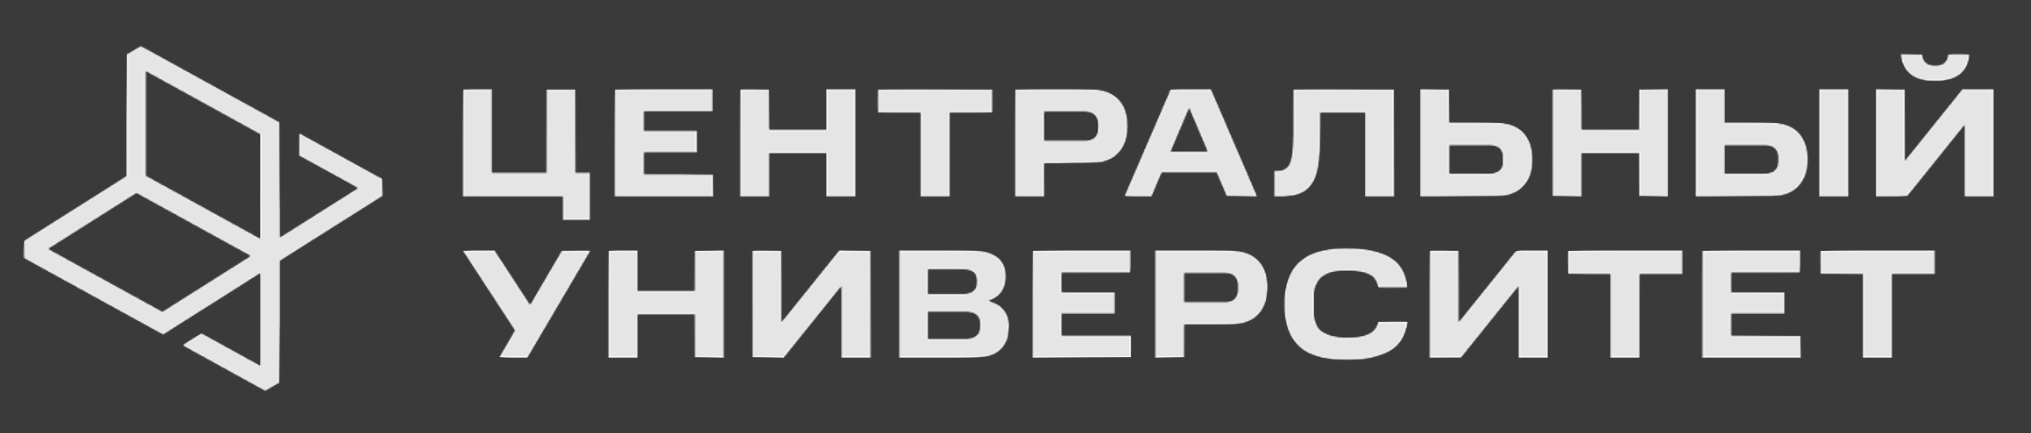


# Курс по прогнозированию временных рядов


# Неделя 10

## 10.9. N-HITS и LSTM


Для базового знакомство с NeuralForecast посетите [Быстрый старт](./Getting_Started.ipynb)

Будем использовать классический абор данных с конкурса M4. Набор данных включает в себя временные ряды из различных областей, таких как финансы, экономика и продажи. В этом примере мы будем использовать подмножество данных Hourly.

Мы будем моделировать каждый временной ряд глобально. Таким образом, вы обучите набор моделей для всего набора данных, а затем выберете лучшую модель для каждого отдельного временного ряда. 


Предположем, что у вас уже установлен `NeuralForecast`. 

Кроме того, мы используем `s3fs` для чтения из файловой системы S3 в AWS, `statsforecast` для построения графиков и `datasetsforecast` для обычных метрик ошибок, таких как MAE или MASE.


В библиотеке  `NeuralForecast` реализованы следующие архитектуры https://nixtlaverse.nixtla.io/neuralforecast/models.html
- Autoformer https://nixtlaverse.nixtla.io/neuralforecast/models.autoformer.html
- BiTCN https://nixtlaverse.nixtla.io/neuralforecast/models.dilated_rnn.html
- DeepAR https://nixtlaverse.nixtla.io/neuralforecast/models.deepar.html
- DeepNPTS https://nixtlaverse.nixtla.io/neuralforecast/models.deepnpts.html
- Dilated RNN https://nixtlaverse.nixtla.io/neuralforecast/models.dilated_rnn.html
- DLinear https://nixtlaverse.nixtla.io/neuralforecast/models.dlinear.html
- FEDformer https://nixtlaverse.nixtla.io/neuralforecast/models.fedformer.html
- GRU https://nixtlaverse.nixtla.io/neuralforecast/models.gru.html
- HINT https://nixtlaverse.nixtla.io/neuralforecast/models.hint.html
- Informer https://nixtlaverse.nixtla.io/neuralforecast/models.informer.html
- iTransformer https://nixtlaverse.nixtla.io/neuralforecast/models.itransformer.html
- KAN https://nixtlaverse.nixtla.io/neuralforecast/models.kan.html
- LSTM https://nixtlaverse.nixtla.io/neuralforecast/models.lstm.html
- MLP https://nixtlaverse.nixtla.io/neuralforecast/models.mlp.html
- N-BEAST https://nixtlaverse.nixtla.io/neuralforecast/models.nbeats.html
- N-Beastx https://nixtlaverse.nixtla.io/neuralforecast/models.nbeatsx.html
- N-Hits https://nixtlaverse.nixtla.io/neuralforecast/models.nhits.html
- N-Linear https://nixtlaverse.nixtla.io/neuralforecast/models.nlinear.html
- PatchTST https://nixtlaverse.nixtla.io/neuralforecast/models.patchtst.html
- RNN https://nixtlaverse.nixtla.io/neuralforecast/models.rnn.html
- StemGNN https://nixtlaverse.nixtla.io/neuralforecast/models.stemgnn.html
- TCN https://nixtlaverse.nixtla.io/neuralforecast/models.tcn.html
- TFT https://nixtlaverse.nixtla.io/neuralforecast/models.tft.html
- Time-LMM https://nixtlaverse.nixtla.io/neuralforecast/models.timellm.html
- TSMixer https://nixtlaverse.nixtla.io/neuralforecast/models.tsmixer.html
- TSMixerx https://nixtlaverse.nixtla.io/neuralforecast/models.tsmixerx.html
- Vanilla Transformer https://nixtlaverse.nixtla.io/neuralforecast/models.vanillatransformer.html


## Чтение данных

Мы будем использовать pandas для чтения набора данных M4 Hourly, хранящихся в файле parquet для повышения эффективности`.

На вход `NeuralForecast` всегда подается кадр данных в [длинном формате](https://www.theanalysisfactor.com/wide-and-long-data/) с тремя столбцами: `unique_id`, `ds` и `y`:

* `unique_id` (строка, int или категория) представляет собой идентификатор серии.

* Столбец `ds` (datestamp или int) должен быть либо целым числом, индексирующим время, либо датой в идеале, например YYYY-MM-DD для даты или YYYY-MM-DD HH:MM:SS для временной метки.

* `y` (числовой) представляет измерение, которое мы хотим спрогнозировать.
Мы переименуем


In [1]:
import pandas as pd

Y_df = pd.read_parquet('https://datasets-nixtla.s3.amazonaws.com/m4-hourly.parquet')

Y_df.head()

,unique_id,ds,y
0,H1,1,605.0
1,H1,2,586.0
2,H1,3,586.0
3,H1,4,559.0
4,H1,5,511.0


Этот набор данных содержит 414 уникальных серий со средним числом наблюдений 900. Для данного примера и в целях воспроизводимости мы выберем только 10 уникальных идентификаторов.


In [3]:
uids = Y_df['unique_id'].unique()[:10] # Select 10 ids
Y_df = Y_df.query('unique_id in @uids').reset_index(drop=True)

Построим несколько графиков с помощью метода `plot` из класса `StatsForecast`. 

Метод StatsForecast.plot использует Plotly по умолчанию. Вы можете изменить его на MatPlotLib, установив engine="matplotlib". 

D:\Users\dmpla\anaconda3\Lib\site-packages\statsforecast\core.py:27: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm


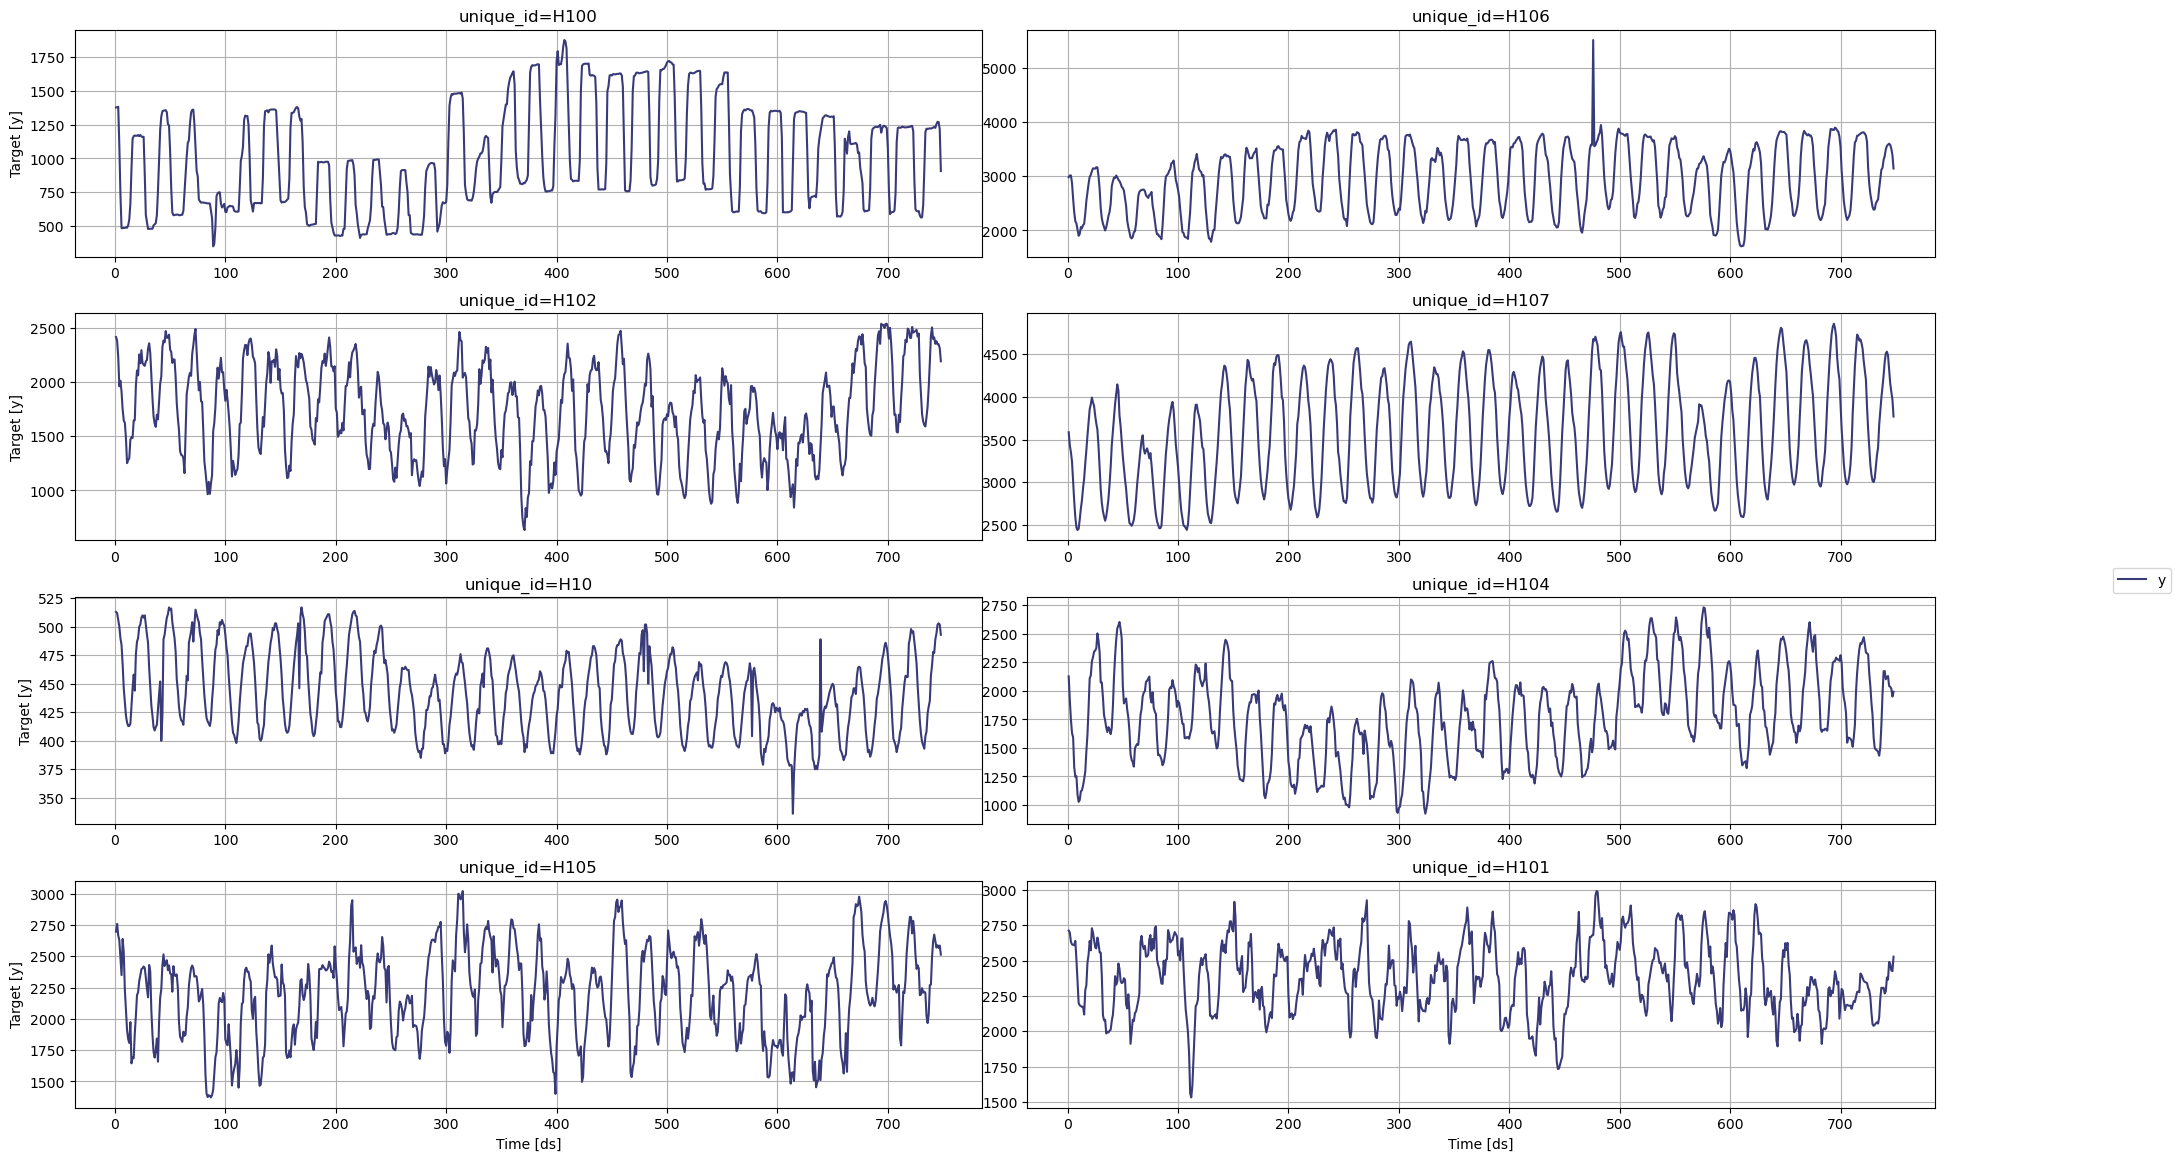

In [5]:
from statsforecast import StatsForecast

StatsForecast.plot(Y_df, engine='matplotlib')

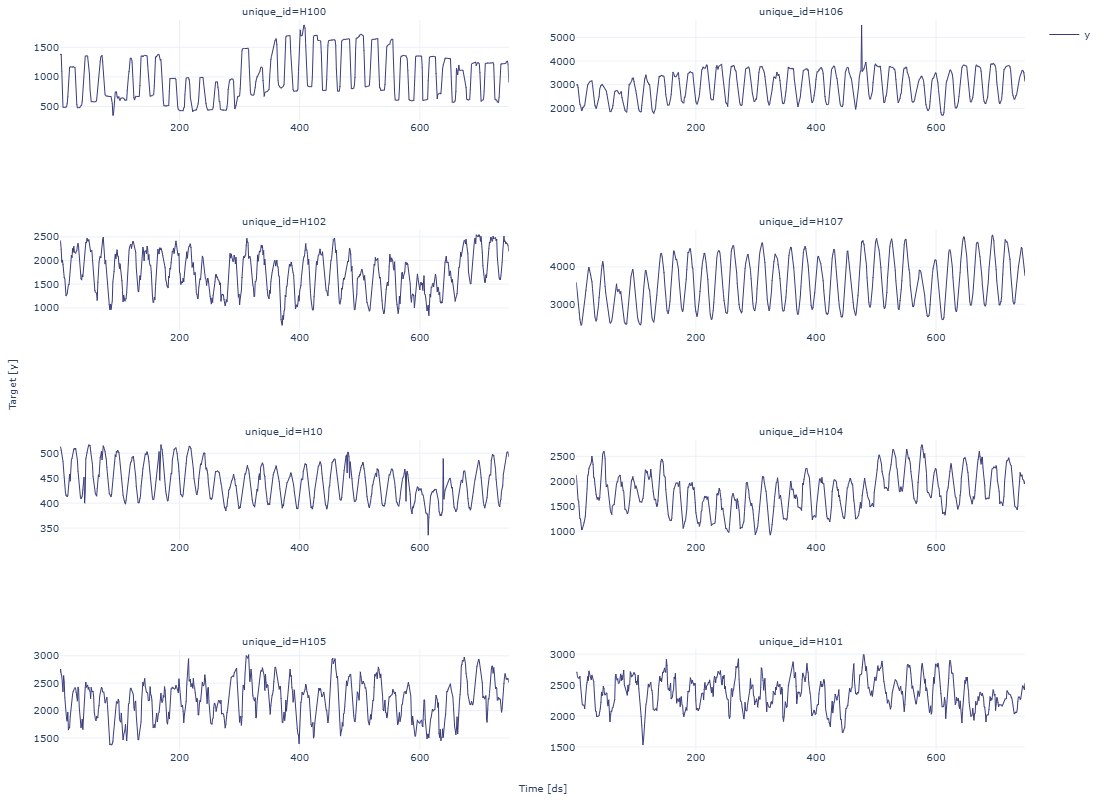

In [7]:
from statsforecast import StatsForecast

StatsForecast.plot(Y_df, engine='plotly')

## Обучение нескольких моделей для многих серий

`NeuralForecast` можено обучать множество моделей на множестве временных рядов.

In [ ]:
from ray import tune

from neuralforecast import NeuralForecast
from neuralforecast.auto import AutoNHITS, AutoLSTM
from neuralforecast.losses.pytorch import MQLoss

Каждая модель `Auto` содержит пространство поиска по умолчанию, которое было протестировано на нескольких крупномасштабных наборах данных. Кроме того, пользователи могут определять специальные пространства поиска, предназначенные для конкретных наборов данных и задач.

Сначала мы создадим пользовательское пространство поиска для моделей `AutoNHITS` и `AutoLSTM`. Поисковые пространства задаются с помощью словарей, где ключи соответствуют гиперпараметрам модели, а значение - функции `Tune`, задающей способ выборки гиперпараметров. Например, для равномерной выборки целых чисел используйте `randint`, а для выборки значений списка - `choice`.


In [ ]:
config_nhits = {
    "input_size": tune.choice([48, 48*2, 48*3]),                    # Length of input window
    "start_padding_enabled": True,
    "n_blocks": 5*[1],                                              # Length of input window
    "mlp_units": 5 * [[64, 64]],                                    # Length of input window
    "n_pool_kernel_size": tune.choice([5*[1], 5*[2], 5*[4],
                                      [8, 4, 2, 1, 1]]),            # MaxPooling Kernel size
    "n_freq_downsample": tune.choice([[8, 4, 2, 1, 1],
                                      [1, 1, 1, 1, 1]]),            # Interpolation expressivity ratios
    "learning_rate": tune.loguniform(1e-4, 1e-2),                   # Initial Learning rate
    "scaler_type": tune.choice([None]),                             # Scaler type
    "max_steps": tune.choice([1000]),                               # Max number of training iterations
    "batch_size": tune.choice([1, 4, 10]),                          # Number of series in batch
    "windows_batch_size": tune.choice([128, 256, 512]),             # Number of windows in batch
    "random_seed": tune.randint(1, 20),                             # Random seed
}

config_lstm = {
    "input_size": tune.choice([48, 48*2, 48*3]),              # Length of input window
    "encoder_hidden_size": tune.choice([64, 128]),            # Hidden size of LSTM cells
    "encoder_n_layers": tune.choice([2,4]),                   # Number of layers in LSTM
    "learning_rate": tune.loguniform(1e-4, 1e-2),             # Initial Learning rate
    "scaler_type": tune.choice(['robust']),                   # Scaler type
    "max_steps": tune.choice([500, 1000]),                    # Max number of training iterations
    "batch_size": tune.choice([1, 4]),                        # Number of series in batch
    "random_seed": tune.randint(1, 20),                       # Random seed
}

Чтобы создать модель `Auto`, необходимо определить:

* `h`: горизонт прогнозирования.
* `loss`: функция потерь при обучении и проверке из `neuralforecast.losses.pytorch`.
* `config`: пространство поиска гиперпараметров. Если `None`, то класс `Auto` будет использовать предопределенное пространство гиперпараметров.
* `search_alg`: алгоритм поиска (из `tune.search`), по умолчанию - случайный поиск. Дополнительную информацию о различных вариантах алгоритмов поиска см. на сайте https://docs.ray.io/en/latest/tune/api_docs/suggestion.html.
* `num_samples`: количество исследуемых конфигураций.

В этом примере мы задаем горизонт `h` равным 48, используем потери `MQLoss` для обучения и проверки, и используем алгоритм поиска по умолчанию.

`MQLoss` (Multi-Quantile loss) рассчитывает среднюю мультиквантильные потери для данного набора квантилей, основанную на абсолютной разнице между предсказанными квантилями и наблюдаемыми значениями.
$$
\mathrm{MQL}(\mathbf{y}_{\tau},[\mathbf{\hat{y}}^{(q_{1})}_{\tau}, ... ,\hat{y}^{(q_{n})}_{\tau}]) = \frac{1}{n} \sum_{q_{i}} \mathrm{QL}(\mathbf{y}_{\tau}, \mathbf{\hat{y}}^{(q_{i})}_{\tau}),
$$
$$
\mathrm{QL}(\mathbf{y}_{\tau}, \mathbf{\hat{y}}^{(q)}_{\tau}) = \frac{1}{H} \sum^{t+H}_{\tau=t+1} \Big( (1-q)\,( \hat{y}^{(q)}_{\tau} - y_{\tau} )_{+} + q\,( y_{\tau} - \hat{y}^{(q)}_{\tau} )_{+} \Big)
$$

In [ ]:
nf = NeuralForecast(
    models=[
        AutoNHITS(h=48, config=config_nhits, loss=MQLoss(), num_samples=5),
        AutoLSTM(h=48, config=config_lstm, loss=MQLoss(), num_samples=2),
    ],
    freq=1
)


Количество образцов, `num_samples`, является важнейшим параметром! Большие значения обычно дают лучшие результаты, поскольку мы исследуем больше конфигураций в пространстве поиска, но это увеличивает время обучения. Большие пространства поиска обычно требуют большего количества образцов. Рекомендуется задавать `num_samples` больше 20.


Далее мы используем класс `Neuralforecast` для обучения модели `Auto`. На этом этапе модели `Auto` автоматически выполняют настройку гиперпараметров, обучая несколько моделей с различными гиперпараметрами, производя прогнозы на валидационном множестве и оценивая их. Лучшая конфигурация выбирается на основе ошибки на валидационном множестве. Только лучшая модель сохраняется и используется в процессе вычисления.

In [ ]:
%%capture
nf.fit(df=Y_df)

2024-01-24 15:20:06,030	INFO worker.py:1724 -- Started a local Ray instance.
2024-01-24 15:20:07,962	INFO tune.py:220 -- Initializing Ray automatically. For cluster usage or custom Ray initialization, call `ray.init(...)` before `Tuner(...)`.
2024-01-24 15:20:07,984	INFO tune.py:592 -- [output] This will use the new output engine with verbosity 0. To disable the new output and use the legacy output engine, set the environment variable RAY_AIR_NEW_OUTPUT=0. For more information, please see https://github.com/ray-project/ray/issues/36949
INFO:lightning_fabric.utilities.seed:Seed set to 17
2024-01-24 15:23:44,794	INFO tune.py:592 -- [output] This will use the new output engine with verbosity 0. To disable the new output and use the legacy output engine, set the environment variable RAY_AIR_NEW_OUTPUT=0. For more information, please see https://github.com/ray-project/ray/issues/36949
INFO:lightning_fabric.utilities.seed:Seed set to 11


Далее мы используем метод `predict` для прогнозирования на ближайшие 48 дней с использованием оптимальных гиперпараметров.

In [ ]:
fcst_df = nf.predict()
fcst_df.columns = fcst_df.columns.str.replace('-median', '')
fcst_df.head()

Predicting: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

,ds,AutoNHITS,AutoNHITS-lo-90,AutoNHITS-lo-80,AutoNHITS-hi-80,AutoNHITS-hi-90,AutoLSTM,AutoLSTM-lo-90,AutoLSTM-lo-80,AutoLSTM-hi-80,AutoLSTM-hi-90
unique_id,,,,,,,,,,,
H1,749,602.886963,569.199036,574.601501,630.768738,636.769409,625.468079,499.371521,510.894897,716.271912,736.001526
H1,750,541.729919,473.846283,492.600922,588.550537,597.792847,572.243530,428.734192,455.636658,689.977905,718.843872
H1,751,498.073456,423.379639,427.707581,554.051636,567.569153,529.019592,378.284241,404.246643,652.972229,695.424255
H1,752,464.102325,383.322998,387.390930,520.259155,537.356018,478.024109,338.814331,365.467773,601.316650,642.860291
H1,753,439.934387,352.066132,368.929199,505.999664,523.350830,444.837830,313.554321,339.722321,558.488464,604.043030


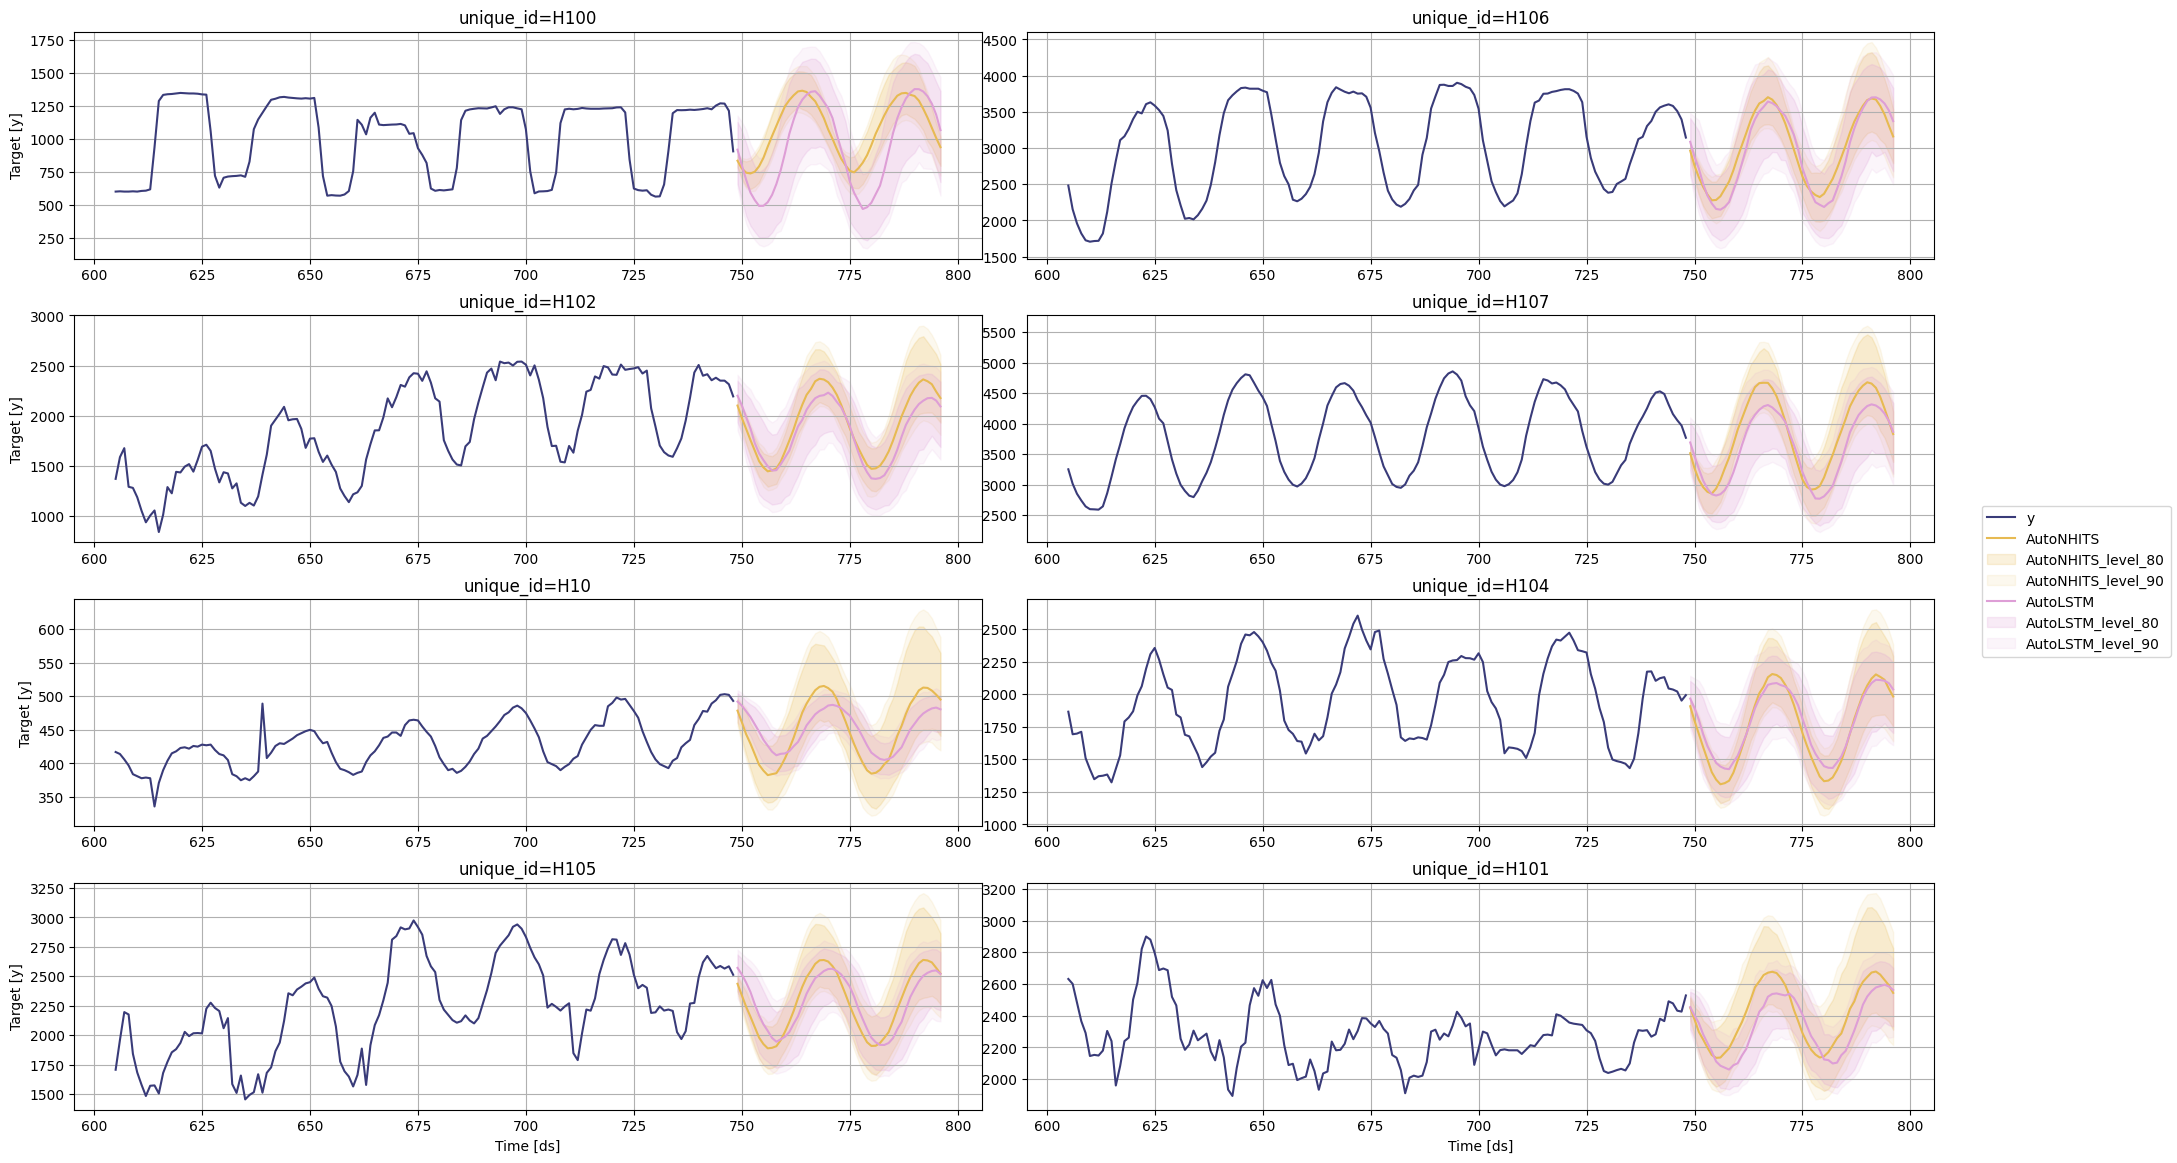

In [ ]:
StatsForecast.plot(Y_df, fcst_df, engine='matplotlib', max_insample_length=48 * 3, level=[80, 90])

Функция `StatsForecast.plot` позволяет выполнить дальнейшую настройку. Например, построить график результатов для разных моделей и уникальных идентификаторов.

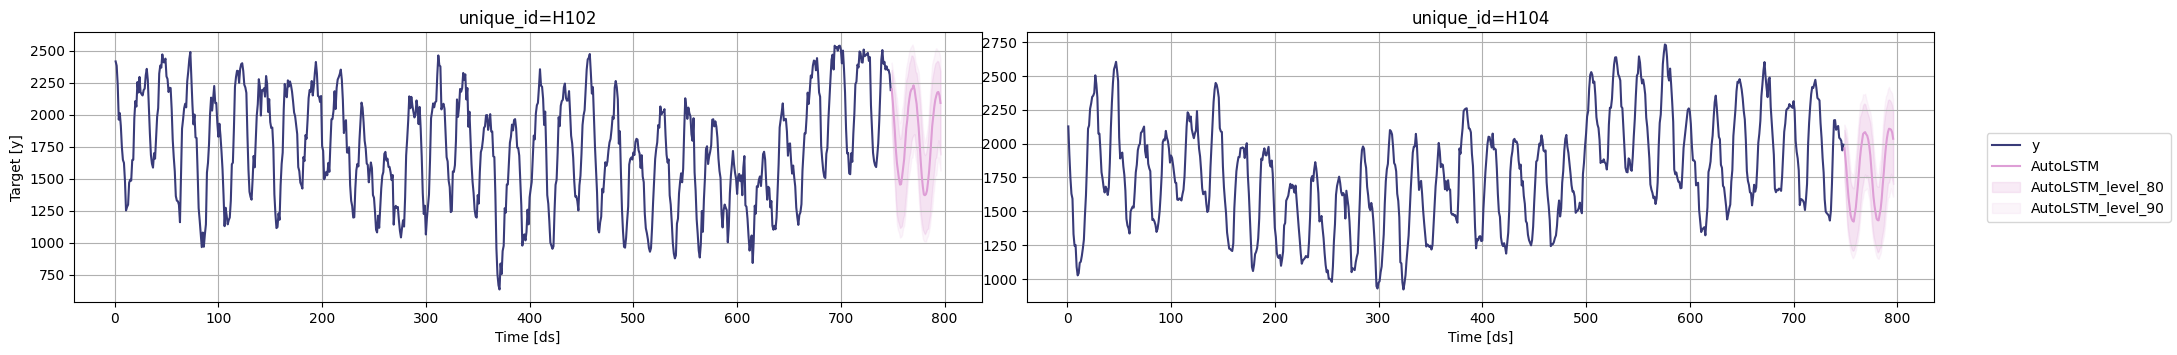

In [ ]:
# Plot to unique_ids and some selected models
StatsForecast.plot(Y_df, fcst_df, models=["AutoLSTM"], unique_ids=["H102", "H104"], level=[80, 90], engine='matplotlib')

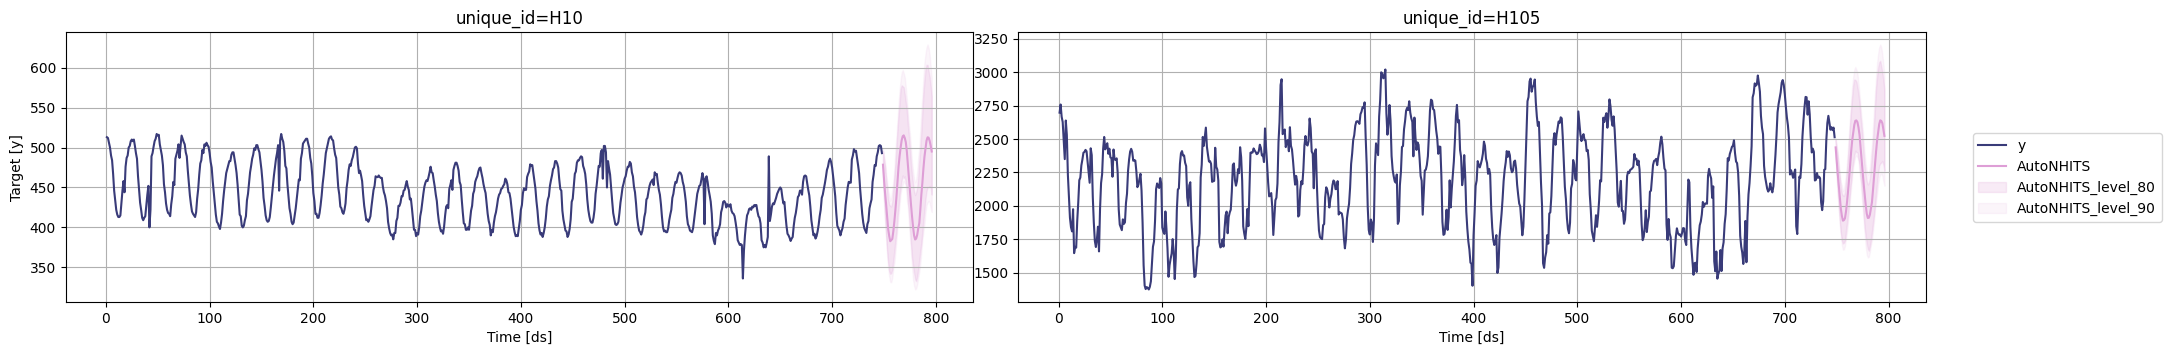

In [ ]:
# Explore other models
StatsForecast.plot(Y_df, fcst_df, models=["AutoNHITS"], unique_ids=["H10", "H105"], level=[80, 90], engine='matplotlib')

## Оценка эффективности модели


В предыдущих шагах мы использовали наши исторические данные для прогнозирования будущего. Однако, чтобы оценить его точность, мы также хотели бы знать, как модель работала в прошлом. Чтобы оценить точность и устойчивость моделей на ваших данных, выполните перекрестную проверку (Cross-Validation)Проведем кв **Кросс-валюлрасширяющимсяящегом.дели.

На следующем графике показана такая стратегия перекрестной валидации:

![](https://raw.githubusercontent.com/Nixtla/statsforecast/main/nbs/imgs/ChainedWindows.gif)


Установка `n_windows=1` отражает традиционное разделение обучения и тестирования, при котором наши исторические данные служат обучающим набором, а последние 48 часов - тестовым набором.



Метод `cross_validation` из класса `NeuralForecast` принимает следующие аргументы.

- `df`: датафрейм обучающих данных

- `step_size` (int): размер шага между каждым окном. Другими словами: как часто вы хотите запускать процессы прогнозирования.
- `n_windows` (int): количество окон, используемых для перекрестной валидации. Другими словами: какое количество процессов прогнозирования в прошлом вы хотите оценить.

In [ ]:
from neuralforecast.auto import AutoNHITS, AutoLSTM
config_nhits = {
    "input_size": tune.choice([48, 48*2, 48*3]),              # Length of input window
    "start_padding_enabled": True,
    "n_blocks": 5*[1],                                              # Length of input window
    "mlp_units": 5 * [[64, 64]],                                  # Length of input window
    "n_pool_kernel_size": tune.choice([5*[1], 5*[2], 5*[4],
                                      [8, 4, 2, 1, 1]]),            # MaxPooling Kernel size
    "n_freq_downsample": tune.choice([[8, 4, 2, 1, 1],
                                      [1, 1, 1, 1, 1]]),            # Interpolation expressivity ratios
    "learning_rate": tune.loguniform(1e-4, 1e-2),                   # Initial Learning rate
    "scaler_type": tune.choice([None]),                             # Scaler type
    "max_steps": tune.choice([1000]),                               # Max number of training iterations
    "batch_size": tune.choice([1, 4, 10]),                          # Number of series in batch
    "windows_batch_size": tune.choice([128, 256, 512]),             # Number of windows in batch
    "random_seed": tune.randint(1, 20),                             # Random seed
}

config_lstm = {
    "input_size": tune.choice([48, 48*2, 48*3]),              # Length of input window
    "encoder_hidden_size": tune.choice([64, 128]),            # Hidden size of LSTM cells
    "encoder_n_layers": tune.choice([2,4]),                   # Number of layers in LSTM
    "learning_rate": tune.loguniform(1e-4, 1e-2),             # Initial Learning rate
    "scaler_type": tune.choice(['robust']),                   # Scaler type
    "max_steps": tune.choice([500, 1000]),                    # Max number of training iterations
    "batch_size": tune.choice([1, 4]),                        # Number of series in batch
    "random_seed": tune.randint(1, 20),                       # Random seed
}
nf = NeuralForecast(
    models=[
        AutoNHITS(h=48, config=config_nhits, loss=MQLoss(), num_samples=5),
        AutoLSTM(h=48, config=config_lstm, loss=MQLoss(), num_samples=2),
    ],
    freq=1
)

In [ ]:
%%capture
cv_df = nf.cross_validation(Y_df, n_windows=2)

2024-01-24 15:30:13,886	INFO tune.py:592 -- [output] This will use the new output engine with verbosity 0. To disable the new output and use the legacy output engine, set the environment variable RAY_AIR_NEW_OUTPUT=0. For more information, please see https://github.com/ray-project/ray/issues/36949
INFO:lightning_fabric.utilities.seed:Seed set to 4
2024-01-24 15:35:22,947	INFO tune.py:592 -- [output] This will use the new output engine with verbosity 0. To disable the new output and use the legacy output engine, set the environment variable RAY_AIR_NEW_OUTPUT=0. For more information, please see https://github.com/ray-project/ray/issues/36949
INFO:lightning_fabric.utilities.seed:Seed set to 18


Объект `cv_df` представляет собой новый датафрейм, включающий следующие столбцы:

- `unique_id`: идентифицирует временной ряд
- `ds`: временной индекс
- `cutoff`: последняя временная метка или временной индекс для n_windows. Если n_windows=1, то одно уникальное значение отсечки, если n_windows=2, то два уникальных значения отсечки.
- `y`: истинное значение
- `model`: столбцы с именем модели и ее подогнанным значением.

In [ ]:
cv_df.columns = cv_df.columns.str.replace('-median', '')

In [ ]:
cv_df.head()

,ds,cutoff,AutoNHITS,AutoNHITS-lo-90,AutoNHITS-lo-80,AutoNHITS-hi-80,AutoNHITS-hi-90,AutoLSTM,AutoLSTM-lo-90,AutoLSTM-lo-80,AutoLSTM-hi-80,AutoLSTM-hi-90,y
unique_id,,,,,,,,,,,,,
H1,700,699,690.389282,563.160461,614.428467,762.368896,771.114624,676.214844,541.614990,568.466675,751.117188,786.542114,684.0
H1,701,699,653.828613,505.149597,548.951660,742.958008,761.703735,608.706421,465.244690,506.063599,706.825012,751.774597,619.0
H1,702,699,555.119019,369.872986,404.331482,678.942383,714.179688,542.682251,393.596924,437.706543,658.288330,703.254028,565.0
H1,703,699,485.946350,299.421173,327.823181,625.317627,669.996765,487.761475,330.585419,375.764771,600.986755,649.803711,532.0
H1,704,699,466.066925,306.259003,325.613464,601.043945,652.358948,459.177795,294.042084,342.660797,579.300537,631.581909,495.0


In [ ]:
for cutoff in cv_df['cutoff'].unique():
    StatsForecast.plot(
        Y_df,
        cv_df.query('cutoff == @cutoff').drop(columns=['y', 'cutoff']),
        max_insample_length=48 * 4,
        unique_ids=['H185'],
        engine='matplotlib'
    )

Теперь давайте оценим эффективность моделей.

In [ ]:
from datasetsforecast.losses import mse, mae, rmse
from datasetsforecast.evaluation import accuracy

In [ ]:
print(cv_df.index.name)
print(Y_df.index.name)

unique_id
None


In [ ]:
cv_df = cv_df.reset_index()
Y_df = Y_df.reset_index()

In [ ]:
evaluation_df = accuracy(cv_df, [mse, mae, rmse], agg_by=['unique_id'])


evaluation_df['best_model'] = evaluation_df.drop(columns=['metric', 'unique_id']).idxmin(axis=1)
evaluation_df.head()

,metric,unique_id,AutoNHITS,AutoLSTM,best_model
0,mae,H1,37.752935,36.376335,AutoLSTM
1,mae,H10,22.389334,12.122053,AutoLSTM
2,mae,H100,197.616424,102.578835,AutoLSTM
3,mae,H101,183.074880,110.979240,AutoLSTM
4,mae,H102,162.100259,220.078158,AutoNHITS


Создайте сводную таблицу с колонкой модели и количеством серий, в которых эта модель показала наилучшие результаты.

In [ ]:
summary_df = evaluation_df.groupby(['metric', 'best_model']).size().sort_values().to_frame()

summary_df = summary_df.reset_index()
summary_df.columns = ['metric', 'model', 'nr. of unique_ids']
summary_df

,metric,model,nr. of unique_ids
0,mae,AutoNHITS,2
1,mse,AutoNHITS,2
2,rmse,AutoNHITS,2
3,mae,AutoLSTM,8
4,mse,AutoLSTM,8
5,rmse,AutoLSTM,8


In [ ]:
summary_df.query('metric == "mse"')

,metric,model,nr. of unique_ids
1,mse,AutoNHITS,2
4,mse,AutoLSTM,8


Вы можете дополнительно изучить результаты, построив график `unique_ids`, в котором побеждает определенная модель.

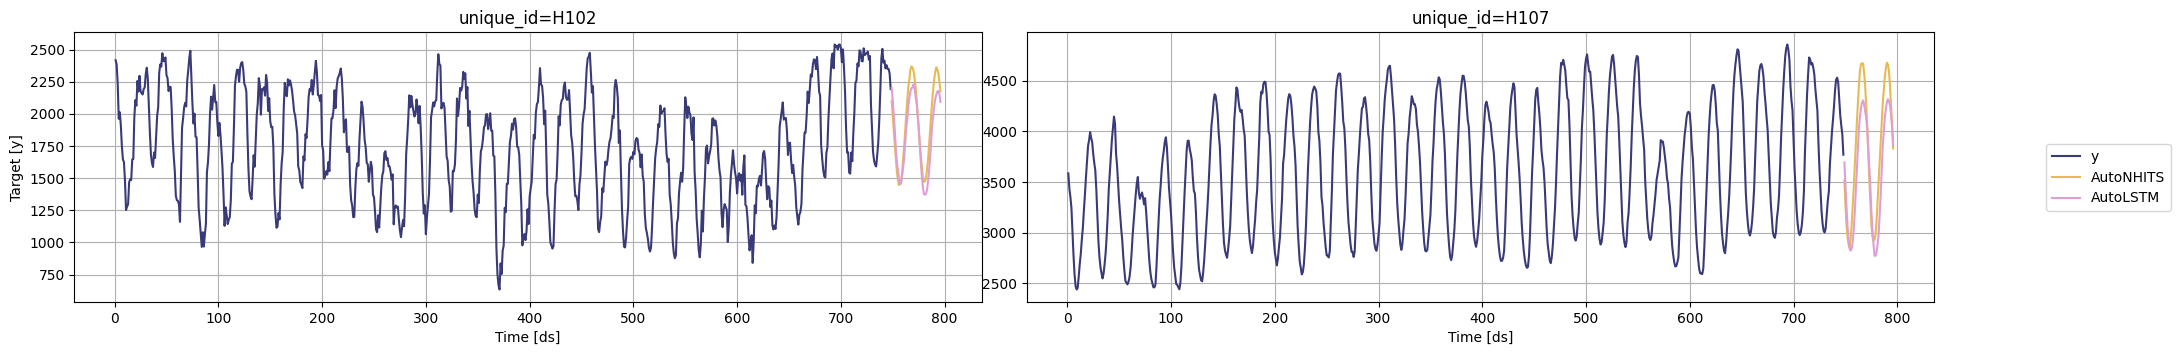

In [ ]:
nhits_ids = evaluation_df.query('best_model == "AutoNHITS" and metric == "mse"')['unique_id'].unique()

StatsForecast.plot(Y_df, fcst_df, unique_ids=nhits_ids, engine='matplotlib')

## Выберите лучшую модель для каждой серии

Определим функцию, которая берет датафрейм с предсказаниями и датафрейм оценки и возвращает датафрейм с наилучшим возможным прогнозом для каждого `unique_id`.

In [ ]:
def get_best_model_forecast(forecasts_df, evaluation_df, metric):
    df = forecasts_df.set_index('ds', append=True).stack().to_frame().reset_index(level=2) # Wide to long
    df.columns = ['model', 'best_model_forecast']
    df = df.join(evaluation_df.query('metric == @metric').set_index('unique_id')[['best_model']])
    df = df.query('model.str.replace("-lo-90|-hi-90", "", regex=True) == best_model').copy()
    df.loc[:, 'model'] = [model.replace(bm, 'best_model') for model, bm in zip(df['model'], df['best_model'])]
    df = df.drop(columns='best_model').set_index('model', append=True).unstack()
    df.columns = df.columns.droplevel()
    df = df.reset_index(level=1)
    return df

Создадим датафрейм с наилучшим прогнозом для каждого `unique_id`.

In [ ]:
prod_forecasts_df = get_best_model_forecast(fcst_df, evaluation_df, metric='mse')

prod_forecasts_df.head()

model,ds,best_model,best_model-hi-90,best_model-lo-90
unique_id,,,,
H1,749,625.468079,736.001526,499.371521
H1,750,572.243530,718.843872,428.734192
H1,751,529.019592,695.424255,378.284241
H1,752,478.024109,642.860291,338.814331
H1,753,444.837830,604.043030,313.554321


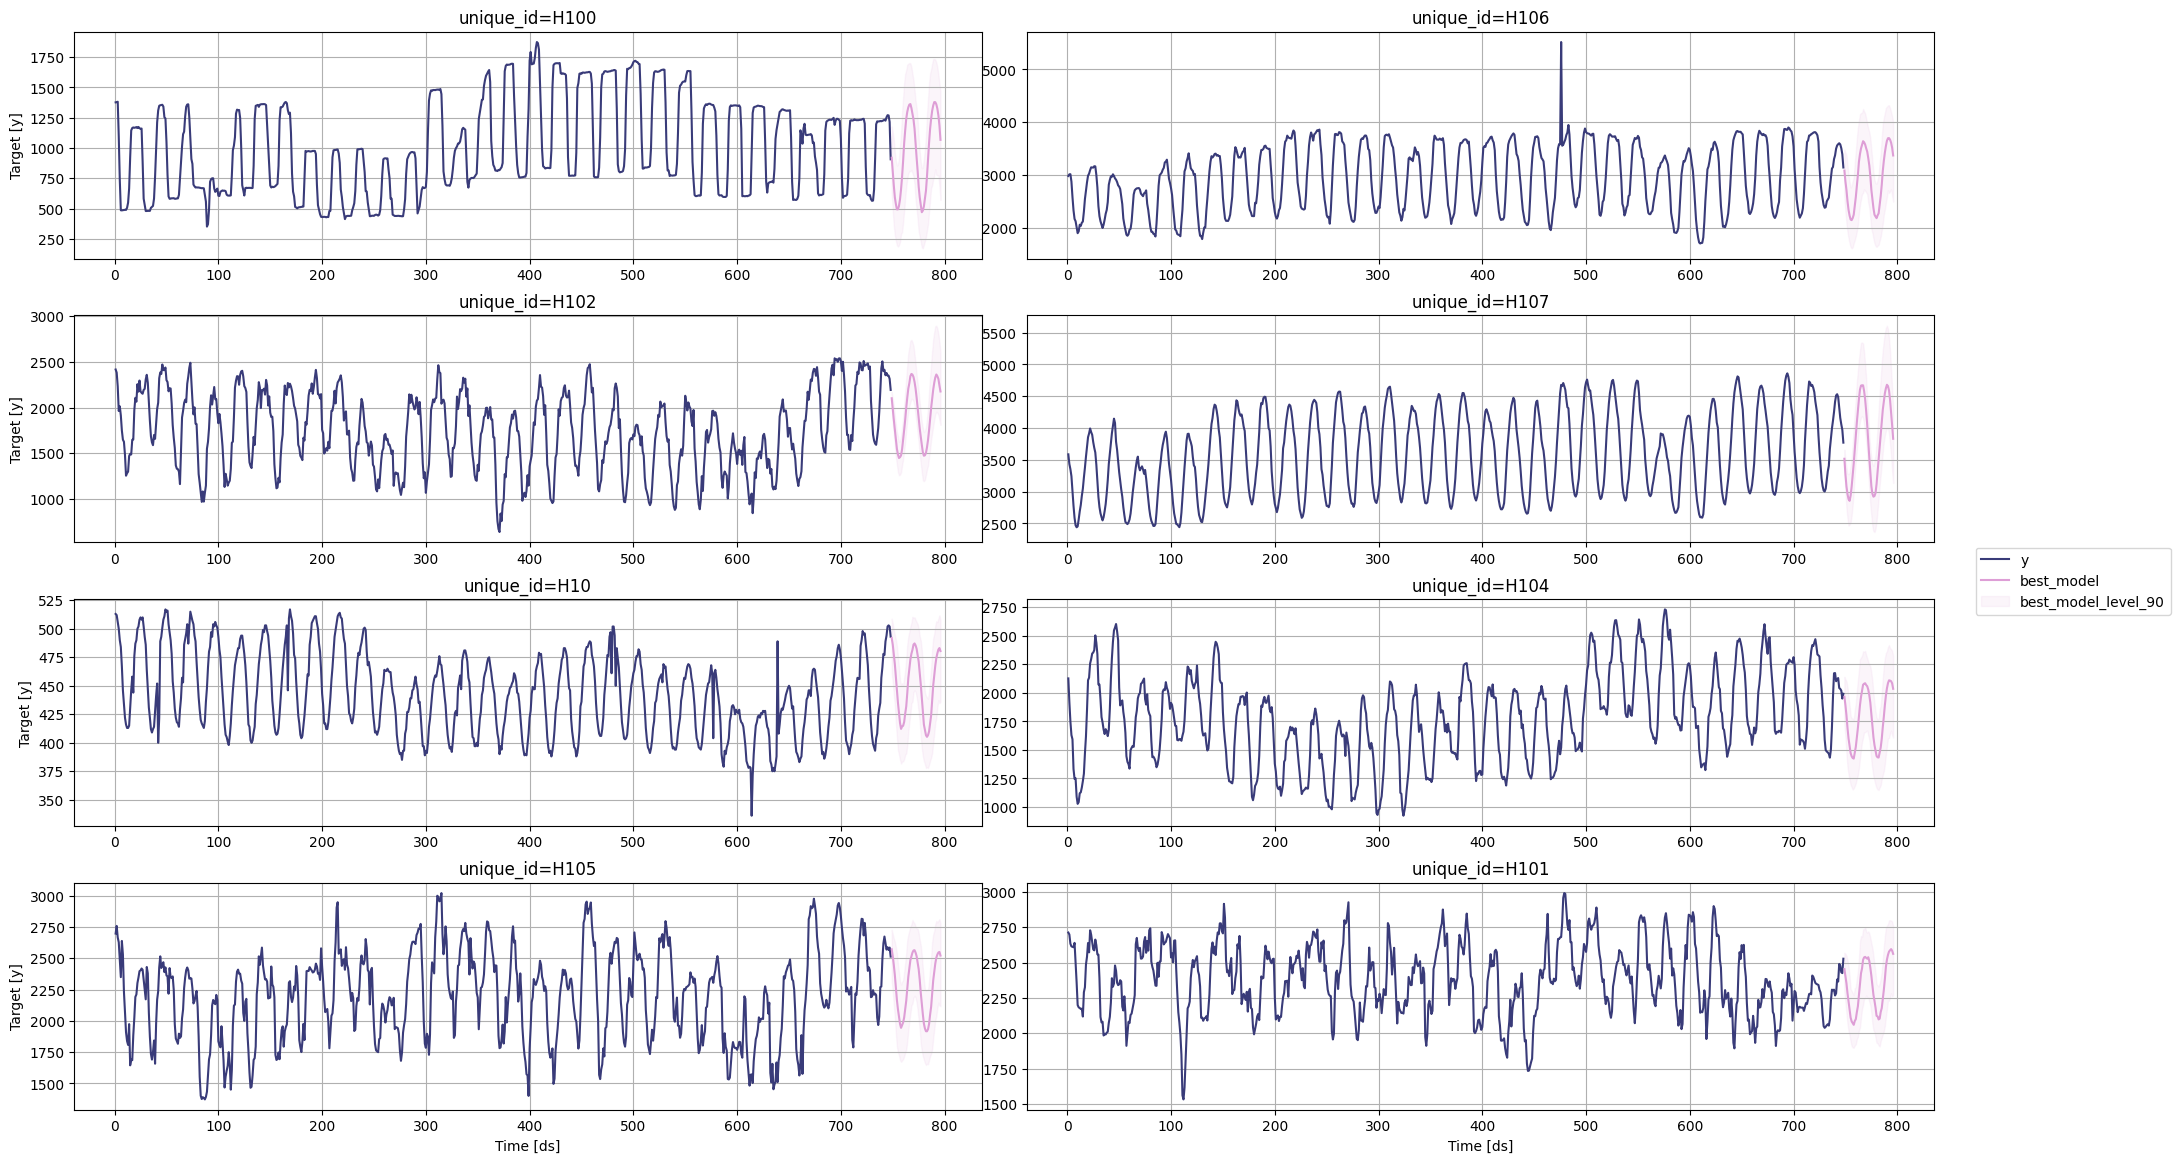

In [ ]:
StatsForecast.plot(Y_df, prod_forecasts_df, level=[90], engine='matplotlib')